# Поиска инсайтов и точек роста

- Автор: Лагода Максим
- Дата: 24.06.2026

С данными сервиса доставки еды «Всё.из.кафе» вы уже работали в одном из проектов базового курса. Тогда вы описывали ключевые метрики продукта — количество пользователей, заказов и выручку.

Однако конкуренты сервиса не дремлют, и руководство ждёт от продукта роста. Найти инсайты, которые позволят сервису повысить показатель удержания пользователей и улучшить взаимодействие с партнёрами, поручено продуктовому аналитику, то есть вам.

Вам необходимо помочь бизнесу ответить на следующие вопросы:
- Как ведут себя пользователи? Как наиболее эффективно выстроить работу с ними, чтобы они продолжали пользоваться продуктом?
- Какой путь проходят пользователи в сервисе? Где «проваливаются»?
- Как улучшить взаимодействие с партнёрами-ресторанами?

### Задачи 

В рамках данного проекта вы проведёте комплексный анализ данных:
- изучите пользовательский путь и проанализируете конверсии через воронки;
- сегментируете пользователей с помощью RFM-модели для оценки лояльности и поведения клиентов;
- кластеризуете рестораны методом K-Means, чтобы выделить группы с разными моделями работы и разработать персонализированные маркетинговые стратегии.

Такой подход позволит ближе познакомиться с работой сервиса, выявить узкие места и предложить решения для удержания пользователей и повышения эффективности сотрудничества с ресторанами.


### Данные

Данные включают следующие сведения:
      
- `visitor_uuid` — идентификатор посетителя. Это идентификатор, который присваивается системой любому новому пользователю вне зависимости от того, зарегистрировался он в продукте или нет.
- `user_id` — идентификатор зарегистрированного пользователя. Присваивается посетителю после создания учётной записи: ввода логина, пароля, адреса доставки и контактных данных.
- `device_type` — тип платформы, с которой посетитель зашёл в продукт.
- `city_id` — город, из которого посетитель зашёл в сервис.
- `source` — рекламный источник привлечения посетителя.
- `first_date` — дата первого посещения продукта.
- `visit_id` — уникальный идентификатор сессии.
- `event` — название аналитического события.
- `datetime` — дата и время события.
- `rest_id` — уникальный идентификатор ресторана (заполняется для заказов, карточек ресторанов и блюд).
- `object_id` — уникальный идентификатор блюда (заполняется для заказов и карточек блюд).
- `order_id` — уникальный идентификатор заказа.
- `revenue` — выручка от заказа (в рублях). Это та сумма, которую пользователь видит при оплате.
- `delivery` — стоимость доставки (в рублях).
- `commission` — комиссия, которую «Всё.из.кафе» берёт с выручки ресторана, в процентах.

    
### План проекта
- Загрузка данных и их предобработка.
- Анализ пользовательского пути новых пользователей.
- RFM сегментация.
- K-Means кластеризация.
- Итоговый вывод и рекомендации.

## 1. Загрузка данных и их предобработка

Загрузите данные и получите первую информацию о них. Проведите необходимую предобработку. Основную информацию о данных и этапы предобработки зафиксируйте в кратком промежуточном выводе.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [4]:
insides_data = pd.read_csv('https://code.s3.yandex.net/datasets/insides_data.csv')

In [5]:
print("Первые 5 строк insides_data:")
display(insides_data.head())

print("\nИнформация о данных insides_data:")
insides_data.info()

print("\nПропуски insides_data:")
print(insides_data.isna().sum())

print("\nПолные дубликаты строк insides_data:")
print(insides_data.duplicated().sum())

Первые 5 строк insides_data:


,visitor_uuid,user_id,device_type,city_id,source,first_date,visit_id,event,datetime,rest_id,object_id,order_id,revenue,delivery,commission
0,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,authorization,2021-05-01 16:07:53,NaN,NaN,NaN,NaN,NaN,NaN
1,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,reg_page,2021-05-01 16:09:16,NaN,NaN,NaN,NaN,NaN,NaN
2,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,confirm_phone,2021-05-01 16:09:19,NaN,NaN,NaN,NaN,NaN,NaN
3,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,login,2021-05-01 16:09:23,NaN,NaN,NaN,NaN,NaN,NaN
4,01b5da38-3022-48ff-87c0-5519247fef1b,567317.0,Desktop,6,Source_B,2021-05-01,171481813,main_page,2021-05-01 16:09:34,2c6095730b514c189ee41c65f03febc3,NaN,NaN,NaN,NaN,NaN



Информация о данных insides_data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205510 entries, 0 to 205509
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   visitor_uuid  205510 non-null  object 
 1   user_id       205510 non-null  float64
 2   device_type   205510 non-null  object 
 3   city_id       205510 non-null  int64  
 4   source        205510 non-null  object 
 5   first_date    205510 non-null  object 
 6   visit_id      205510 non-null  int64  
 7   event         205510 non-null  object 
 8   datetime      205510 non-null  object 
 9   rest_id       166915 non-null  object 
 10  object_id     21308 non-null   float64
 11  order_id      7008 non-null    float64
 12  revenue       7008 non-null    float64
 13  delivery      7008 non-null    float64
 14  commission    21308 non-null   float64
dtypes: float64(6), int64(2), object(7)
memory usage: 23.5+ MB

Пропуски insides_data:
visitor_uuid       

In [6]:
insides_data['first_date'] = pd.to_datetime(insides_data['first_date'])
insides_data['datetime'] = pd.to_datetime(insides_data['datetime'])

In [7]:
print("\nПроверка user_id:")
print(f"Пропущенных user_id: {insides_data['user_id'].isna().sum()}")
print(f"Уникальных user_id: {insides_data['user_id'].nunique()}")
print(f"Уникальных visitor_uuid: {insides_data['visitor_uuid'].nunique()}")


Проверка user_id:
Пропущенных user_id: 0
Уникальных user_id: 8473
Уникальных visitor_uuid: 8891


In [8]:
sessions_per_user = insides_data.groupby('user_id')['visitor_uuid'].nunique()
print("\nСтатистика по сессиям на пользователя:")
print(sessions_per_user.describe())


Статистика по сессиям на пользователя:
count    8473.000000
mean        1.064676
std         0.303924
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         9.000000
Name: visitor_uuid, dtype: float64


In [9]:
print("\nРаспределение событий:")
print(insides_data['event'].value_counts())


Распределение событий:
main_page        145607
login             18581
object_page       12132
authorization      9983
reg_page           5684
add_to_cart        5627
confirm_phone      4347
order              3549
Name: event, dtype: int64


In [10]:
orders_data = insides_data[insides_data['event'] == 'order']
print(f"\nВсего заказов: {len(orders_data)}")
print(f"Заказов с пропущенной выручкой: {orders_data['revenue'].isna().sum()}")
print(f"Заказов с пропущенным rest_id: {orders_data['rest_id'].isna().sum()}")


Всего заказов: 3549
Заказов с пропущенной выручкой: 0
Заказов с пропущенным rest_id: 0


In [11]:
print("\nСводная статистика:")
print(f"Всего строк: {len(insides_data)}")
print(f"Всего уникальных пользователей (user_id): {insides_data['user_id'].nunique()}")
print(f"Всего уникальных посетителей (visitor_uuid): {insides_data['visitor_uuid'].nunique()}")
print(f"Всего уникальных сессий (visit_id): {insides_data['visit_id'].nunique()}")


Сводная статистика:
Всего строк: 205510
Всего уникальных пользователей (user_id): 8473
Всего уникальных посетителей (visitor_uuid): 8891
Всего уникальных сессий (visit_id): 11406


**Данные:**
- Загружено 205 510 строк и 15 столбцов.
- Данные содержат события пользователей сервиса доставки «Всё.из.кафе».
- Период данных: с 1 мая 2021 года по 3 июля 2021 года.

**Качество данных:**
- Пропуски в данных являются логичными и связаны с тем, что не все события содержат информацию о ресторанах, блюдах и заказах.
- Дубликаты строк отсутствуют.
- Заказы не содержат пропусков в выручке и идентификаторах ресторанов.

**Пользователи и сессии:**
- Уникальных зарегистрированных пользователей: 8 473
- Уникальных посетителей: 8 891
- Уникальных сессий: 11 406
- 75% пользователей имеют только 1 сессию, что говорит о низком удержании.

**События:**
- Наиболее частые события: `main_page` (145 607), `login` (18 581), `object_page` (12 132).
- Всего заказов: 3 549.
- Заказов от новых пользователей: 2 058 (58% от всех заказов).

**Созданные признаки:**
- `event_date` — дата события (из `datetime`).
- `is_new_user` — признак, указывающий, что событие произошло в день первого визита пользователя.

---

## 2. Анализ пользовательского пути

Маркетологи стали замечать следующее: деньги на рекламу по-прежнему тратятся, а заказов стало меньше. И это несмотря на то, что приложение скачивается и устанавливается так же активно, как раньше. Складывается ощущение, что пользователи где-то теряются. При этом доля заказов с десктопной версии приложения увеличилась по сравнению с мобильной.

Разработчики говорят, что последние обновления мобильной версии приложения не должны были повлиять на каталог блюд или его выбор для заказа и последующей оплаты доставки, так как изменения касались нового алгоритма подтверждения мобильного телефона и адреса доставки.

С помощью воронок изучите общий пользовательский путь новых пользователей, затем сравните поведение пользователей мобильной и десктопной версий приложения. 

**Задача 2.1.** Постройте и визуализируйте общую воронку (по всем данным), затем опишите пользовательский путь: какие этапы представлены, какова их последовательность, на каком (или на каких) этапах теряется большая часть новых пользователей.
    
При решении постройте две воронки: 
- **классическую воронку** — доля от первого шага в процентах
- **step-by-step** — с конверсией от предыдущего этапа.

Предполагается, что пользователь проходит такой путь к оформлению доставки блюда из ресторанов:
1. `authorization` — авторизация пользователя — запуск приложения.
2. `main_page` — загрузка основной страницы приложения.
2. `reg_page` — переход на страницу регистрации.
2. `confirm_phone` — подтверждение телефона (окончание процесса регистрации).
2. `object_page` — страница блюда.
2. `add_to_cart` — переход в корзину.
2. `order` — оформление заказа.    


            step  users  conversion_from_first_%  conversion_from_previous_%
0  authorization   7410                    100.0                         NaN
1      main_page   6537                     88.2                        88.2
2       reg_page   5417                     73.1                        82.9
3  confirm_phone   4190                     56.5                        77.3
4    object_page   3453                     46.6                        82.4
5    add_to_cart   2899                     39.1                        84.0
6          order   2416                     32.6                        83.3


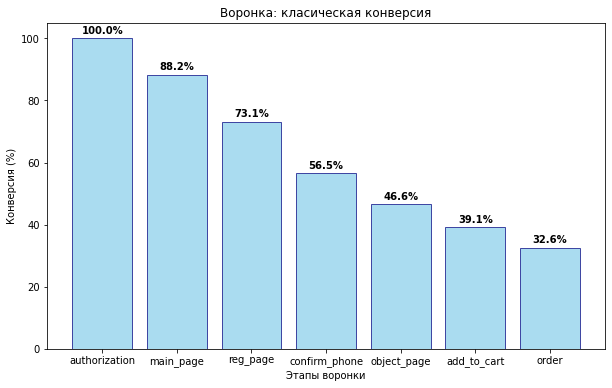

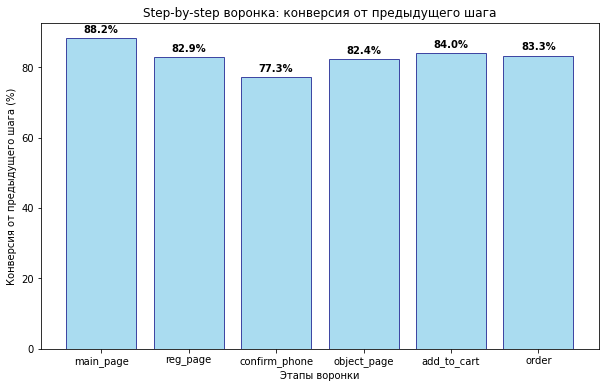

In [12]:
funnel_steps = ['authorization', 'main_page', 'reg_page', 'confirm_phone', 'object_page', 'add_to_cart', 'order']

funnel_insides_data_steps = insides_data[insides_data['event'].isin(funnel_steps)]
funnel_counts = funnel_insides_data_steps.groupby('event')['user_id'].nunique().reindex(funnel_steps)

funnel_insides_data = pd.DataFrame({
    'step': funnel_counts.index,
    'users': funnel_counts.values
})

first_step_users = funnel_insides_data['users'].iloc[0]
funnel_insides_data['conversion_from_first_%'] = (funnel_insides_data['users'] / first_step_users * 100).round(1)
funnel_insides_data['conversion_from_previous_%'] = (funnel_insides_data['users'] / funnel_insides_data['users'].shift(1) * 100).round(1)

print(f'\n{funnel_insides_data.head(7)}')

plt.figure(figsize=(10, 6))

steps_for_plot = funnel_insides_data['step']
conversions = funnel_insides_data['conversion_from_first_%']

plt.bar(steps_for_plot, conversions, color='skyblue', edgecolor='navy', alpha=0.7)

for i, (step, conv) in enumerate(zip(steps_for_plot, conversions)):
    plt.text(i, conv + 1, f'{conv:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Воронка: класическая конверсия')
plt.ylabel('Конверсия (%)')
plt.xlabel('Этапы воронки')
plt.show()

plt.figure(figsize=(10, 6))

steps_for_plot = funnel_insides_data['step'].iloc[1:]
conversions = funnel_insides_data['conversion_from_previous_%'].iloc[1:]

plt.bar(steps_for_plot, conversions, color='skyblue', edgecolor='navy', alpha=0.7)

for i, (step, conv) in enumerate(zip(steps_for_plot, conversions)):
    plt.text(i, conv + 1, f'{conv:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Step-by-step воронка: конверсия от предыдущего шага')
plt.ylabel('Конверсия от предыдущего шага (%)')
plt.xlabel('Этапы воронки')
plt.show()

**Общая воронка (все пользователи):**
- Общая конверсия от первого запуска до заказа: 32.6%.
- Наибольшая потеря происходит на этапе `object_page` → `add_to_cart` (конверсия 82.4%).
- Пользователи активно доходят до страницы блюда, но теряются при добавлении в корзину.

**Задача 2.2.** Сравните пользовательский путь в двух приложениях: в мобильной версии и десктопной. Для этого постройте и визуализируйте **две воронки step-by-step**: для новых пользователей **мобильной** и **десктопной** версий приложения.
    
Сравните результаты между собой и проанализируйте, есть ли различия в пользовательском пути для различных приложений. Результаты сравнения опишите в небольшом **промежуточном выводе**.

            step  mobile  desktop
0      main_page    83.3     91.1
1       reg_page    88.4     79.4
2  confirm_phone    55.1     90.2
3    object_page    72.5     85.8
4    add_to_cart    86.7     82.9
5          order    85.8     82.3


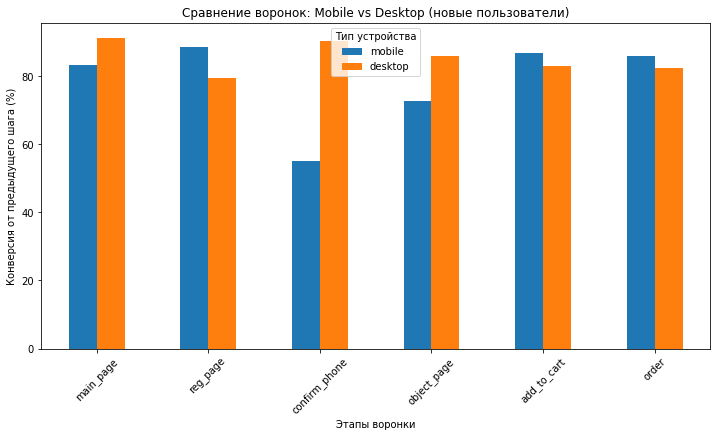

In [13]:
mobile_users = insides_data[insides_data['device_type'] == 'Mobile']
desktop_users = insides_data[insides_data['device_type'] == 'Desktop']

funnel_steps = ['authorization', 'main_page', 'reg_page', 'confirm_phone', 'object_page', 'add_to_cart', 'order']

counts_desktop = desktop_users[desktop_users['event'].isin(funnel_steps)]
counts_desktop_agg = counts_desktop.groupby('event')['user_id'].nunique().reindex(funnel_steps)
desktop_funnel = (counts_desktop_agg / counts_desktop_agg.shift(1) * 100).round(1)

counts_mobile = mobile_users[mobile_users['event'].isin(funnel_steps)]
counts_mobile_agg = counts_mobile.groupby('event')['user_id'].nunique().reindex(funnel_steps)
mobile_funnel = (counts_mobile_agg / counts_mobile_agg.shift(1) * 100).round(1)

funnel_compare = pd.DataFrame({
    'step': funnel_steps[1:],
    'mobile': mobile_funnel[1:].values,
    'desktop': desktop_funnel[1:].values
})

print(funnel_compare)

funnel_compare.set_index('step').plot(kind='bar', figsize=(12, 6))
plt.title('Сравнение воронок: Mobile vs Desktop (новые пользователи)')
plt.ylabel('Конверсия от предыдущего шага (%)')
plt.xlabel('Этапы воронки')
plt.xticks(rotation=45)
plt.legend(title='Тип устройства')
plt.show()

**Сравнение Mobile vs Desktop:**
- **Критическая проблема в мобильной версии:** Конверсия на этапе `confirm_phone` составляет всего 55.1% (против 90.2% в десктопной версии). Это провал в 35 процентных пунктов.
- **Desktop:** лучше на этапах `main_page` (91.1% vs 83.3%), `object_page` (85.8% vs 72.5%) и `confirm_phone` (90.2% vs 55.1%).
- **Mobile:** лучше на этапах `reg_page` (88.4% vs 79.4%), `add_to_cart` (86.7% vs 82.9%) и `order` (85.8% vs 82.3%).

**Ключевые инсайты:**
1. Основная проблема — мобильная версия на этапе подтверждения телефона.
2. Новые пользователи теряются на этапе выбора блюда.
3. Десктопная версия показывает более стабильную конверсию на всех этапах.

---

## 3. RFM сегментация

У сервиса доставки еды не такое высокое удержание пользователей: в первый день возвращается около 14% посетителей, а на седьмой день и того меньше — около 4–5%. Маркетологи хотят запустить несколько рекламных кампаний, направленных на удержание платящих пользователей и их возврат в сервис, если они давно не совершали заказы.

Для этого необходимо сегментировать пользователей на различные поведенческие сегменты с помощью RFM-сегментации по трём показателям: 
- **давность** (Recency), 
- **частота покупок** (Frequency), 
- **сумма трат** (Monetary).

В качестве даты анализа установите **03 июля 2021 года**.

**Задача 3.1.** Для каждого покупателя посчитайте:
- количество дней с последней покупки — давность (R);
- частоту покупок (F);
- стоимость всех покупок — сумму трат (M).
    
В качестве даты анализа установите **03 июля 2021 года**. После этого постройте три гистограммы и проанализируйте их.

Всего пользователей с заказами: 2416


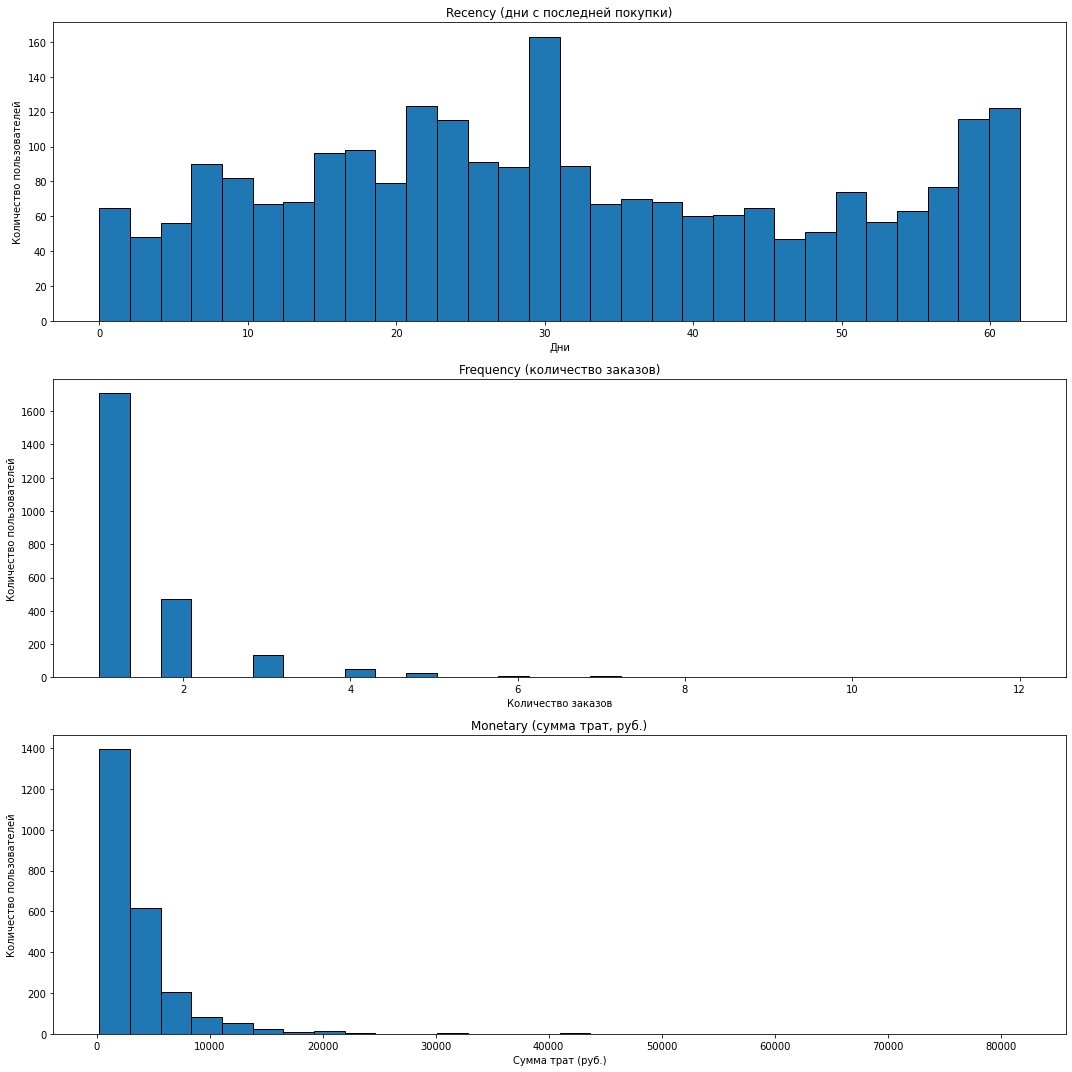


Статистика по RFM-метрикам:
             user_id      recency    frequency      monetary
count    2416.000000  2416.000000  2416.000000   2416.000000
mean   535932.551738    31.086093     1.468957   3720.171429
std    143745.266073    17.444239     0.950901   4036.352731
min      5506.000000     0.000000     1.000000    235.200000
25%    558738.250000    17.000000     1.000000   1512.000000
50%    591033.500000    29.000000     1.000000   2590.000000
75%    615221.000000    46.000000     2.000000   4443.117000
max    679837.000000    62.000000    12.000000  81690.000000


In [14]:
orders_data = insides_data[insides_data['event'] == 'order'].copy()

analysis_date = pd.to_datetime('2021-07-03')
orders_data['recency_days'] = (analysis_date - orders_data['datetime']).dt.days

rfm_data = orders_data.groupby('user_id').agg(
    recency=('recency_days', 'min'),  
    frequency=('order_id', 'count'),   
    monetary=('revenue', 'sum')
).reset_index()

print(f"Всего пользователей с заказами: {len(rfm_data)}")

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].hist(rfm_data['recency'], bins=30, edgecolor='black')
axes[0].set_title('Recency (дни с последней покупки)')
axes[0].set_xlabel('Дни')
axes[0].set_ylabel('Количество пользователей')

axes[1].hist(rfm_data['frequency'], bins=30, edgecolor='black')
axes[1].set_title('Frequency (количество заказов)')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество пользователей')

axes[2].hist(rfm_data['monetary'], bins=30, edgecolor='black')
axes[2].set_title('Monetary (сумма трат, руб.)')
axes[2].set_xlabel('Сумма трат (руб.)')
axes[2].set_ylabel('Количество пользователей')

plt.tight_layout()
plt.show()

print("\nСтатистика по RFM-метрикам:")
print(rfm_data.describe())

**Задача 3.2.** Выделите **RFM-сегменты** и изучите распределение пользователей по ним.
    
Примените следующие подходы к выделению RFM сегментов:
- **Recency** — разделите на три равные группы.
- **Frequency** —  разделите на три группы: 
    - пользователи с 1 заказом (F-сегмент с небольшим количеством заказов);
    - пользователи с 2 заказами (F-сегмент со средним количеством заказов);
    - пользователи с 3 и более заказами (F-сегмент с большим количеством заказов).
- **Monetary** — разделите на три группы по 33-му и 66-му перцентилям.
    
После этого посчитайте количество покупателей в каждом сегменте, сделайте промежуточные выводы и напишите рекомендации.

   user_id  recency  frequency  monetary  r  f  m rfm_group
0   5506.0       32          2   3752.00  2  2  3       223
1   6291.0       57          1   1750.00  1  1  1       111
2   6820.0       41          1   1260.14  2  1  1       211

Распределение по RFM-сегментам:
111    247
112    216
113     75
121     16
122     45
123     85
132      8
133     41
211    281
212    237
213    122
221      8
222     59
223    115
231      1
232      9
233    102
311    246
312    186
313     99
321      9
322     48
323     88
332      5
333     68
Name: rfm_group, dtype: int64


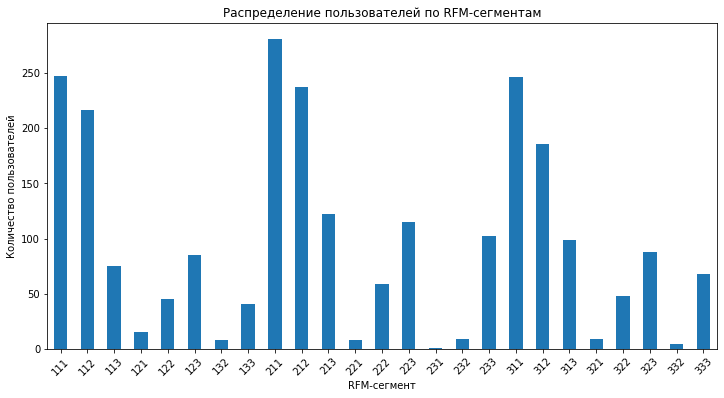

In [15]:
recency_bins = np.linspace(rfm_data['recency'].min(), rfm_data['recency'].max(), 4)
rfm_data['r'] = pd.cut(rfm_data['recency'], bins=recency_bins, labels=[3, 2, 1], include_lowest=True)
rfm_data['f'] = rfm_data['frequency'].apply(lambda x: 1 if x == 1 else (2 if x == 2 else 3))
rfm_data['m'] = pd.qcut(rfm_data['monetary'], q=3, labels=[1, 2, 3])

rfm_data[['r', 'f', 'm']] = rfm_data[['r', 'f', 'm']].astype('str')
rfm_data['rfm_group'] = rfm_data['r'] + rfm_data['f'] + rfm_data['m']

print(rfm_data.head(3))
print("\nРаспределение по RFM-сегментам:")
print(rfm_data['rfm_group'].value_counts().sort_index())

plt.figure(figsize=(12, 6))
rfm_data['rfm_group'].value_counts().sort_index().plot(kind='bar')
plt.title('Распределение пользователей по RFM-сегментам')
plt.xlabel('RFM-сегмент')
plt.ylabel('Количество пользователей')
plt.xticks(rotation=45)
plt.show()

In [16]:
# Код ревьюера:
display(rfm_data.groupby('r')['recency'].max())

# Рассчитаем три равных интервала:
(rfm_data['recency'].max() - rfm_data['recency'].min())  / 3

r
1    62
2    41
3    20
Name: recency, dtype: int64

20.666666666666668

**Общая информация:**
- Всего покупателей: 2 416 (пользователи, совершившие хотя бы один заказ).
- Большинство пользователей (более 60%) совершили только 1 заказ.
- Пользователей с 3+ заказами: ~7.5%.

**Распределение по RFM-метрикам:**
- **Recency:** Средняя давность с последней покупки - 31 день. Распределение равномерное, что говорит о низком возврате пользователей.
- **Frequency:** Ярко выраженный пик на 1 заказе (более 60% пользователей).
- **Monetary:** Большинство пользователей тратят до 5 000 руб., есть небольшое число выбросов с высокими тратами.

**RFM-сегменты:**
- Всего 25 сегментов из 27 возможных.
- **Отсутствуют сегменты 131 и 331** - пользователей с 3+ заказами, которые при этом давно не покупали и имеют низкий или средний чек, нет. Это логично: лояльные клиенты либо остаются активными, либо уходят полностью.
- 68 человек - VIP-ядро (сегмент 333), 3+ заказа, высокий чек, хорошая давность.
- ~20-25% - потенциальные VIP (2-3 заказа, высокий чек).
- **Самые большие сегменты:** 211 - (281 пользователь), 111 - (247), 311 - (246), 212 - (237), 112 - (216) - это пользователи с 1 заказом (~70% покупателей - с одним заказом, главная зона роста).

**Ключевые инсайты:**
1. Отсутствуют сегменты 131 и 331 - это означает, что в сервисе нет пользователей с тремя и более заказами, которые при этом давно не покупали (R=1) и имеют низкий или средний чек.
2.  ~70% всех покупателей сосредоточены в сегментах с одним заказом (F=1).
3. В сервисе сформировалось ядро лояльных VIP-клиентов — сегмент 333 насчитывает 68 человек.
4. Около 20-25% пользователей имеют 2-3 заказа и высокие траты (сегменты 123, 223, 323, 233). Это потенциальные VIP-клиенты

---

## 4. K-Means кластеризация

Чтобы лучше понимать поведение ресторанов и предлагать им персонализированные условия сотрудничества, а также создавать персонализированные предложения для пользователей, маркетологи запросили кластеризацию ресторанов по следующим параметрам:
- общее количество заказов;
- средняя стоимость заказа;
- общее число заказанных уникальных блюд (ассортимент ресторана).

С помощью метода K-Means разделите рестораны на кластеры, отражающие различные модели работы и целевые сегменты. Это позволяет выделить группы ресторанов с похожими характеристиками и разрабатывать для них эффективные маркетинговые стратегии.

**Задача 4.1.** Подготовьте данные для кластеризации и для каждого ресторана подсчитайте:
- общее количество заказов;
- средняя стоимость заказа;
- общее число заказанных уникальных блюд (ассортимент ресторана).

In [17]:
orders_cluster = insides_data[insides_data['event'] == 'order']

restaurant_features = orders_cluster.groupby('rest_id').agg(
    total_orders=('order_id', 'count'),
    avg_order_value=('revenue', 'mean'),
    unique_dishes=('object_id', 'nunique')
).reset_index()

print(f"Количество ресторанов: {len(restaurant_features)}")
print(restaurant_features.head())
print(restaurant_features.describe())

Количество ресторанов: 21
                            rest_id  total_orders  avg_order_value  \
0  1be5a933aab34fbab594bebba48e976e           144      2260.180222   
1  1d6bb74687104fa1953924c9684fe624           108      2959.256481   
2  2c6095730b514c189ee41c65f03febc3             8      1673.000000   
3  3247a3b5f9494812a3c1a73c5b61f004            33      2777.209697   
4  39b7eab4f4704ed2886fafe171489960            33      2011.269697   

   unique_dishes  
0             28  
1             19  
2              4  
3              4  
4              5  
       total_orders  avg_order_value  unique_dishes
count     21.000000        21.000000      21.000000
mean     169.000000      2557.595053      15.285714
std      315.844899       900.370846      23.698403
min        5.000000      1507.735289       1.000000
25%       23.000000      1874.545455       4.000000
50%       77.000000      2369.043478       6.000000
75%      135.000000      2959.256481      13.000000
max     1199.000000    

**Задача 4.2.** Нормализуйте данные и найдите оптимальное количество кластеров, использовав метод `.inertia_`. Постройте график зависимости инерции от числа кластеров (метод «локтя») и предположите оптимальное количество кластеров.

In [18]:
features = ['total_orders', 'avg_order_value', 'unique_dishes']
X = restaurant_features[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Среднее после нормализации:", X_scaled.mean(axis=0).round(2))
print("Стандартное отклонение после нормализации:", X_scaled.std(axis=0).round(2))

Среднее после нормализации: [ 0.  0. -0.]
Стандартное отклонение после нормализации: [1. 1. 1.]


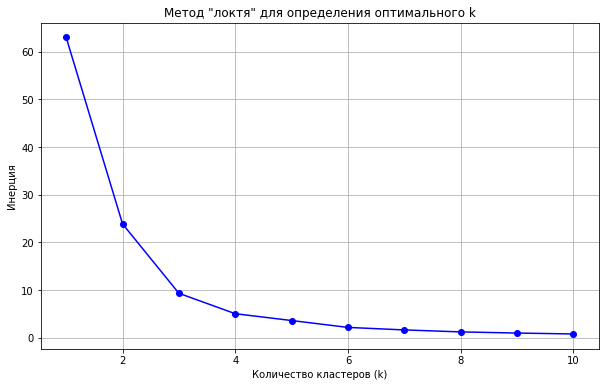

In [19]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, 'o-', color='blue')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Инерция')
plt.title('Метод "локтя" для определения оптимального k')
plt.grid(True)
plt.show()

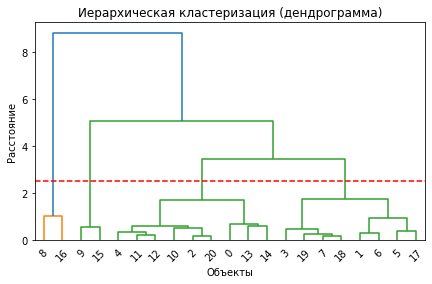

In [20]:
# Код ревьюера:
# Создадим таблицу связей:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(X_scaled, method = 'ward')

# Визуализируем таблицу связей:
plt.figure(figsize=(7, 4))  
dendrogram(linked, orientation='top')

plt.axhline(y=2.5, color='r', linestyle='--')  
plt.title("Иерархическая кластеризация (дендрограмма)")
plt.xlabel("Объекты")
plt.ylabel("Расстояние")

plt.show()

**Задача 4.3.** Проведите кластеризацию, проанализируйте полученные результаты и рассчитайте средние значения по каждому кластеру.
    
После этого визуализируйте результаты, чтобы проследить зависимость признаков друг от друга. Постройте две визуализации, на которые нанесите все кластеры:
- средний чек в зависимости от количества заказов;
- количество блюд в зависимости от количества заказов.

После этого опишите каждый кластер в промежуточном выводе. 

In [21]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
restaurant_features['cluster'] = kmeans.fit_predict(X_scaled)

print("Распределение ресторанов по кластерам:")
print(restaurant_features['cluster'].value_counts().sort_index())

Распределение ресторанов по кластерам:
0    11
1     2
2     6
3     2
Name: cluster, dtype: int64


In [22]:
cluster_means = restaurant_features.groupby('cluster').agg({
    'total_orders': 'mean',
    'avg_order_value': 'mean',
    'unique_dishes': 'mean'
}).round(2)

print("\nСредние значения по кластерам:")
print(cluster_means)


Средние значения по кластерам:
         total_orders  avg_order_value  unique_dishes
cluster                                              
0               71.73          1931.62           8.64
1             1100.00          2498.83          83.00
2               65.33          3024.75           9.17
3               84.00          4657.77           2.50


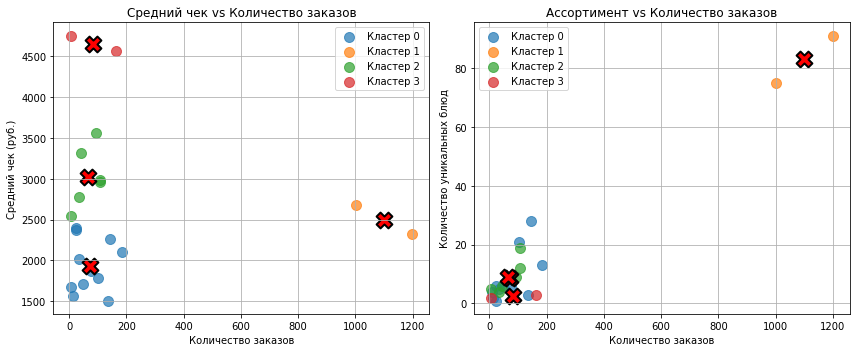

In [23]:
centroids_scaled = kmeans.cluster_centers_

centroids_original = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_original, columns=['total_orders', 'avg_order_value', 'unique_dishes'])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for cluster in sorted(restaurant_features['cluster'].unique()):
    data = restaurant_features[restaurant_features['cluster'] == cluster]
    plt.scatter(data['total_orders'], data['avg_order_value'], 
                label=f'Кластер {cluster}', s=100, alpha=0.7)

for i, cluster in enumerate(sorted(restaurant_features['cluster'].unique())):
    plt.scatter(
        centroids_original[i, 0],  # total_orders
        centroids_original[i, 1],  # avg_order_value
        s=250, c='red', edgecolors='black', linewidths=2, marker='X',
    )

plt.xlabel('Количество заказов')
plt.ylabel('Средний чек (руб.)')
plt.legend()
plt.title('Средний чек vs Количество заказов')
plt.grid(True)

plt.subplot(1, 2, 2)
for cluster in sorted(restaurant_features['cluster'].unique()):
    data = restaurant_features[restaurant_features['cluster'] == cluster]
    plt.scatter(data['total_orders'], data['unique_dishes'], 
                label=f'Кластер {cluster}', s=100, alpha=0.7)

for i, cluster in enumerate(sorted(restaurant_features['cluster'].unique())):
    plt.scatter(
        centroids_original[i, 0],  # total_orders
        centroids_original[i, 2],  # unique_dishes
        s=250, c='red', edgecolors='black', linewidths=2, marker='X',
    )

plt.xlabel('Количество заказов')
plt.ylabel('Количество уникальных блюд')
plt.legend()
plt.title('Ассортимент vs Количество заказов')
plt.grid(True)

plt.tight_layout()
plt.show()

**Подготовка данных:**
- Для кластеризации использованы 3 признака: количество заказов, средний чек, ассортимент.
- Всего ресторанов: 21.
- Данные нормализованы с помощью `StandardScaler`.

**Метод "локтя":**
- Оптимальное количество кластеров: k=4 (определено по графику инерции).

**Ключевые инсайты:**
1. **Кластер 0 (Базовый)** - 11 ресторанов, основная масса ресторанов, стратегия - поддержка и стимулирование роста.
2. **Кластер 1 (Лидеры)** - 2 ресторана, основной объем заказов(в среднем 1100 заказов), широкий ассортимент(83 блюда), стратегия — поддержка и стимулирование роста.
3. **Кластер 2 (Премиум)** - 6 ресторанов, высокий чек(~3 025 руб.), средние показатели(9 блюд).
4. **Кластер 3 (Эксклюзив)** - 2 ресторана, максимальный чек(~4 658 руб.), узкий ассортимент(3 блюда), их ценность в премиальности.

---

## 5. Итоговый вывод и рекомендации

Сформулируйте общий вывод. Зафиксируйте основные результаты и инсайты, которые, на ваш взгляд, помогут бизнесу улучшить продукт.

Выводы должны быть краткими и ёмкими, ведь их будут читать ваш заказчик, продуктовый менеджер и продуктовая команда.

**Итоговый вывод и рекомендации**

**Ключевые проблемы пользовательского пути:**
- Общая конверсия в заказ - 33%.
- Мобильная версия теряет 45% пользователей на этапе подтверждения телефона (конверсия 55% против 91% в десктопе).
- Основная потеря новых пользователей - на этапе просмотра блюда → корзина (конверсия 64%).

**Удержание и RFM:**
- 75% пользователей имеют только одну сессию, 60% покупателей совершают 1 заказ.
- Есть ядро лояльных VIP-клиентов (сегмент 333 - 68 пользователей), которых нужно поддерживать.
- Крупнейшие сегменты - пользователи с 1 заказом (почти 70% всех покупателей), которые не возвращаются. Это главная зона роста для удержания.
- Пользователи с 2-3 заказами и высокими тратами (потенциальные VIP) составляют значительную группу (~20-25%).

**Рестораны (4 кластера):**
- **Базовый сегмент (11)** - основная масса, требует стимулирования роста.
- **Лидеры (2)** - генерируют основной объем заказов (в среднем 1100 заказов), широкий ассортимент (83 блюда), требуют индивидуальных условий.
- **Премиальный (6)** - высокий чек (~3 025 руб.), средний ассортимент (9 блюд), ценность в маржинальности.
- **Эксклюзив-премиум (2)** - максимальный чек (~4 658 руб.), узкий ассортимент (3 блюда), требуют эксклюзивного позиционирования.

**Рекомендации:**
1. **Мобильная версия** — провести исследование мобильного этапа подтверждения телефона: проверить UX-сценарий, техническую стабильность и корректность работы нового алгоритма.
2. **Удержание**
    - Для сегмента 1 заказ (70% покупателей): реактивировать пользователей с 1 заказом через бонусы, внедрить программу лояльности.
    - Для сегментов с 2+ заказами и высокими тратами (потенциальные VIP): стимулировать рост покупок путем введения персональных предложений, программ лояльности.
    - Для сегмента 333 (VIP): поддерживать вовлеченность путем экслклюзивных предложений, персональных акций.
3. **Рестораны**
    - Для "Лидеров" (Кл.1): Предложить индивидуальные условия сотрудничества, эксклюзивные промо-акции для увеличения среднего чека, совместные маркетинговые кампании.
    - Для "Премиум" (Кл.2): Помогать с продвижением, делать акцент на уникальности и качестве в маркетинговых материалах, работа с премиальной аудиторией.
    - Для "Эксклюзив-премиум" (Кл.3): Эксклюзивное позиционирование, работа с корпоративными клиентами, развитие ассортимента для привлечения новых пользователей.
    - Для "Базового" сегмента (Кл.0): Стимулировать их рост через совместные акции, программы поддержки, обучение работе с сервисом и увеличение ассортимента.